In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob

files = glob.glob("/kaggle/input/**/*.csv", recursive=True)
print(files)
CSV_PATH = next(p for p in files if "aw_fb_data" in p)

TARGET = "activity"
EPOCHS = 200
LR = 0.3
BATCH_SIZE = 32
LAMBDA = 1e-5
SEED = 42

df = pd.read_csv(CSV_PATH).dropna()
print(df.shape)
print(df.columns.tolist())
print(df[TARGET].value_counts())
df.head()

['/kaggle/input/datasets/aleespinosa/apple-watch-and-fitbit-data/aw_fb_data.csv', '/kaggle/input/datasets/aleespinosa/apple-watch-and-fitbit-data/data_for_weka_aw.csv', '/kaggle/input/datasets/aleespinosa/apple-watch-and-fitbit-data/data_for_weka_fb.csv']
(6264, 20)
['Unnamed: 0', 'X1', 'age', 'gender', 'height', 'weight', 'steps', 'hear_rate', 'calories', 'distance', 'entropy_heart', 'entropy_setps', 'resting_heart', 'corr_heart_steps', 'norm_heart', 'intensity_karvonen', 'sd_norm_heart', 'steps_times_distance', 'device', 'activity']
activity
Lying             1379
Running 7 METs    1114
Running 5 METs    1002
Running 3 METs     950
Sitting            930
Self Pace walk     889
Name: count, dtype: int64


,Unnamed: 0,X1,age,gender,height,weight,steps,hear_rate,calories,distance,entropy_heart,entropy_setps,resting_heart,corr_heart_steps,norm_heart,intensity_karvonen,sd_norm_heart,steps_times_distance,device,activity
0,1,1,20,1,168.0,65.4,10.771429,78.531302,0.344533,0.008327,6.221612,6.116349,59.0,1.000000,19.531302,0.138520,1.000000,0.089692,apple watch,Lying
1,2,2,20,1,168.0,65.4,11.475325,78.453390,3.287625,0.008896,6.221612,6.116349,59.0,1.000000,19.453390,0.137967,1.000000,0.102088,apple watch,Lying
2,3,3,20,1,168.0,65.4,12.179221,78.540825,9.484000,0.009466,6.221612,6.116349,59.0,1.000000,19.540825,0.138587,1.000000,0.115287,apple watch,Lying
3,4,4,20,1,168.0,65.4,12.883117,78.628260,10.154556,0.010035,6.221612,6.116349,59.0,1.000000,19.628260,0.139208,1.000000,0.129286,apple watch,Lying
4,5,5,20,1,168.0,65.4,13.587013,78.715695,10.825111,0.010605,6.221612,6.116349,59.0,0.982816,19.715695,0.139828,0.241567,0.144088,apple watch,Lying


In [2]:
drop_cols = [c for c in df.columns if c.lower().startswith("unnamed") or c == "X1"]
df = df.drop(columns=drop_cols)

classes = sorted(df[TARGET].unique())
K = len(classes)
y = df[TARGET].map({c: i for i, c in enumerate(classes)}).values
X = pd.get_dummies(df.drop(columns=[TARGET]), drop_first=True).astype(float).values

# stratified 80/20 split
rng = np.random.default_rng(SEED)
tr, te = [], []
for k in range(K):
    idx_k = rng.permutation(np.where(y == k)[0])
    cut = int(0.8 * len(idx_k))
    tr += list(idx_k[:cut])
    te += list(idx_k[cut:])
tr, te = rng.permutation(tr), rng.permutation(te)

X_train, X_test, y_train, y_test = X[tr], X[te], y[tr], y[te]

mu, sd = X_train.mean(0), X_train.std(0)
sd[sd == 0] = 1
X_train = np.c_[np.ones(len(X_train)), (X_train - mu) / sd]
X_test = np.c_[np.ones(len(X_test)), (X_test - mu) / sd]

# labels as +1 / -1 matrix (one column per class)
def to_pm(y, K):
    Y = -np.ones((len(y), K))
    Y[np.arange(len(y)), y] = 1
    return Y

Y_train, Y_test = to_pm(y_train, K), to_pm(y_test, K)

print("Classes:", classes)
print("Train:", X_train.shape, "Test:", X_test.shape)
# Random Fourier Features: approximates an RBF kernel
D = 500
d = X_train.shape[1] - 1
GAMMA = 1.0 / d

rff_rng = np.random.default_rng(123)
W_rff = rff_rng.normal(0, np.sqrt(2 * GAMMA), size=(d, D))
b_rff = rff_rng.uniform(0, 2 * np.pi, size=D)

def rff(Xb):
    Z = np.sqrt(2.0 / D) * np.cos(Xb[:, 1:] @ W_rff + b_rff)
    return np.c_[np.ones(len(Xb)), Z]

X_train = rff(X_train)
X_test = rff(X_test)
print("After RFF:", X_train.shape, X_test.shape)

Classes: ['Lying', 'Running 3 METs', 'Running 5 METs', 'Running 7 METs', 'Self Pace walk', 'Sitting']
Train: (5010, 18) Test: (1254, 18)
After RFF: (5010, 501) (1254, 501)


In [3]:
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import accuracy_score, f1_score

Xtr, Xte = X_train[:, 1:], X_test[:, 1:]   # without bias column

lin = LinearSVC(C=1.0, max_iter=20000).fit(Xtr, y_train)
p = lin.predict(Xte)
print("LinearSVC  acc:", accuracy_score(y_test, p), " macro-F1:", f1_score(y_test, p, average="macro"))

rbf = SVC(kernel="rbf", C=10, gamma="scale").fit(Xtr, y_train)
p = rbf.predict(Xte)
print("RBF SVC    acc:", accuracy_score(y_test, p), " macro-F1:", f1_score(y_test, p, average="macro"))

print("Majority baseline:", np.bincount(y_test).max() / len(y_test))

LinearSVC  acc: 0.5143540669856459  macro-F1: 0.49771370363706824
RBF SVC    acc: 0.6435406698564593  macro-F1: 0.637970299999527
Majority baseline: 0.22009569377990432


In [4]:
def hinge_loss(X, Ypm, W):
    margins = Ypm * (X @ W)
    return np.sum(np.maximum(0, 1 - margins)) / len(X) + 0.5 * LAMBDA * np.sum(W[1:] ** 2)

def gradient(X, Ypm, W):
    margins = Ypm * (X @ W)
    mask = (margins < 1).astype(float)
    g = -(X.T @ (mask * Ypm)) / len(X)
    reg = LAMBDA * W
    reg[0] = 0                      # no regularization on bias
    return g + reg

def predict(X, W):
    return np.argmax(X @ W, axis=1)

def metrics(y_true, y_pred, K):
    acc = np.mean(y_true == y_pred)
    precs, recs, f1s = [], [], []
    for k in range(K):
        tp = np.sum((y_true == k) & (y_pred == k))
        fp = np.sum((y_true != k) & (y_pred == k))
        fn = np.sum((y_true == k) & (y_pred != k))
        p = tp / (tp + fp) if (tp + fp) else 0.0
        r = tp / (tp + fn) if (tp + fn) else 0.0
        f = 2 * p * r / (p + r) if (p + r) else 0.0
        precs.append(p); recs.append(r); f1s.append(f)
    return acc, np.mean(precs), np.mean(recs), np.mean(f1s)

In [5]:
OPT_NAME = "Batch GD"
W = np.zeros((X_train.shape[1], K))
history = []
for epoch in range(EPOCHS):
    g = gradient(X_train, Y_train, W)
    W -= LR * g
    history.append(hinge_loss(X_train, Y_train, W))

=== Batch GD ===
Accuracy : 0.3589
Precision: 0.4642  (macro)
Recall   : 0.3343  (macro)
F1-score : 0.2812  (macro)
Loss     : 2.0103


Predicted,Lying,Running 3 METs,Running 5 METs,Running 7 METs,Self Pace walk,Sitting
Actual,,,,,,
Lying,179,67,0,18,10,2
Running 3 METs,40,131,0,4,10,5
Running 5 METs,32,109,9,36,14,1
Running 7 METs,88,26,0,99,10,0
Self Pace walk,40,101,0,7,29,1
Sitting,112,44,0,17,10,3


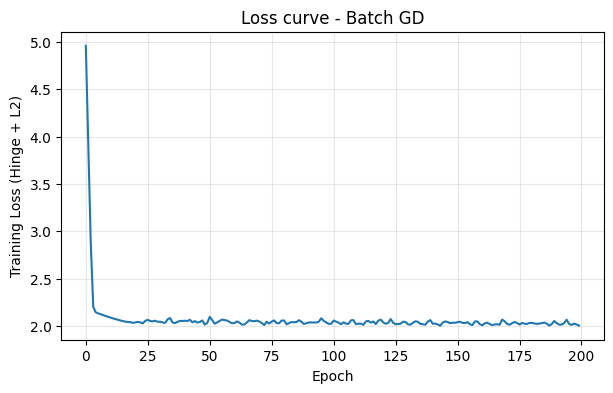

In [6]:
pred = predict(X_test, W)
acc, prec, rec, f1 = metrics(y_test, pred, K)
test_loss = hinge_loss(X_test, Y_test, W)

print(f"=== {OPT_NAME} ===")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}  (macro)")
print(f"Recall   : {rec:.4f}  (macro)")
print(f"F1-score : {f1:.4f}  (macro)")
print(f"Loss     : {test_loss:.4f}")

actual = pd.Series([classes[i] for i in y_test], name="Actual")
predicted = pd.Series([classes[i] for i in pred], name="Predicted")
display(pd.crosstab(actual, predicted))

plt.figure(figsize=(7, 4))
plt.plot(history)
plt.xlabel("Epoch")
plt.ylabel("Training Loss (Hinge + L2)")
plt.title(f"Loss curve - {OPT_NAME}")
plt.grid(alpha=0.3)
plt.show()